Dataset: Adult Census Income (UCI Machine Learning Repository)
Source URL: https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data

In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

cols = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df = pd.read_csv(url, names=cols, skipinitialspace=True)

df = df.replace("?", np.nan)
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip().str.rstrip(".")

target = "income"
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(26048, 14) (6513, 14)
income
<=50K    0.759175
>50K     0.240825
Name: proportion, dtype: float64
income
<=50K    0.759251
>50K     0.240749
Name: proportion, dtype: float64


Splitting into train and test before any data processing prevents data leakage by ensuring information from the test set never influences preprocessing parameters. The test set must remain unseen to provide an unbiased estimate of real-world generalization performance.

In [14]:
from sklearn.impute import SimpleImputer, KNNImputer

affected_col = "occupation"

df_drop = X_train.dropna(subset=[affected_col])

freq_imp = SimpleImputer(strategy="most_frequent")
df_mode = X_train.copy()
df_mode[affected_col] = freq_imp.fit_transform(X_train[[affected_col]]).ravel()

num_col = "age"
knn_imp = KNNImputer(n_neighbors=5)
knn_sample = X_train[[num_col]].copy()
knn_res = knn_imp.fit_transform(knn_sample)

print(df_drop[num_col].mean(), df_drop[num_col].std())
print(df_mode[num_col].mean(), df_mode[num_col].std())
print(np.mean(knn_res), np.std(knn_res))

38.589373464373466 13.641016069423069
38.589373464373466 13.641016069423069
38.589373464373466 13.640754223081997


I would keep mode imputation for categorical columns and median/KNN imputation for numerical columns to avoid discarding valid records through row dropping.

In [15]:
col_outlier = "hours-per-week"

q25, q75 = X_train[col_outlier].quantile(0.25), X_train[col_outlier].quantile(0.75)
iqr = q75 - q25
iqr_mask = (X_train[col_outlier] < (q25 - 1.5 * iqr)) | (X_train[col_outlier] > (q75 + 1.5 * iqr))

mean_val, std_val = X_train[col_outlier].mean(), X_train[col_outlier].std()
z_mask = np.abs((X_train[col_outlier] - mean_val) / std_val) > 3

p1, p99 = X_train[col_outlier].quantile(0.01), X_train[col_outlier].quantile(0.99)
cap_mask = (X_train[col_outlier] < p1) | (X_train[col_outlier] > p99)

overlap = (iqr_mask & z_mask & cap_mask).sum()

print(iqr_mask.sum())
print(z_mask.sum())
print(cap_mask.sum())
print(overlap)

7225
361
412
248


I chose percentile capping at the 1st and 99th percentiles because it reins in extreme values without discarding valid work-hour data.

In [16]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

X_train_enc = X_train.copy()
initial_cols = X_train_enc.shape[1]

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
gender_ohe = ohe.fit_transform(X_train_enc[["sex"]])
cols_after_ohe = initial_cols - 1 + gender_ohe.shape[1]

edu_order = [
    "Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th",
    "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters", "Prof-school", "Doctorate"
]
ord_enc = OrdinalEncoder(categories=[edu_order], handle_unknown="use_encoded_value", unknown_value=-1)
X_train_enc["education_ord"] = ord_enc.fit_transform(X_train_enc[["education"]])
cols_after_ord = cols_after_ohe + 1

freq_map = X_train_enc["native-country"].value_counts(normalize=True).to_dict()
X_train_enc["country_freq"] = X_train_enc["native-country"].map(freq_map)
cols_after_freq = cols_after_ord + 1

print(initial_cols)
print(cols_after_ohe)
print(cols_after_ord)
print(cols_after_freq)

14
15
16
17


In [17]:
unseen_df = pd.DataFrame({"sex": ["UnknownGender", "Male", "Female"]})

encoded_unseen = ohe.transform(unseen_df)
print(encoded_unseen)

[[0. 0.]
 [0. 1.]
 [1. 0.]]


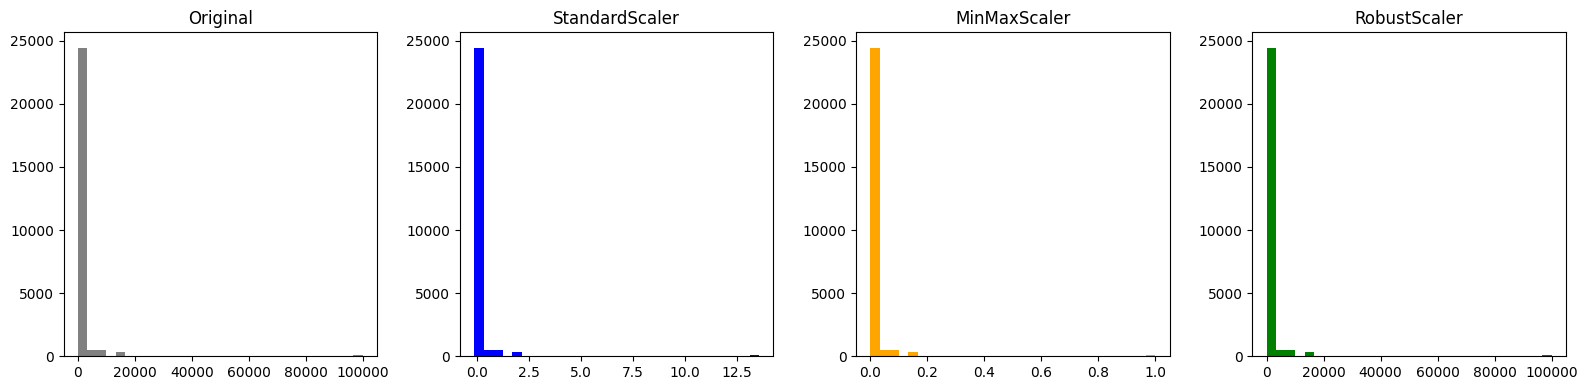

In [18]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

skew_col = "capital-gain"
data_col = X_train[[skew_col]]

std_scaled = StandardScaler().fit_transform(data_col)
minmax_scaled = MinMaxScaler().fit_transform(data_col)
robust_scaled = RobustScaler().fit_transform(data_col)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].hist(data_col, bins=30, color="gray")
axes[0].set_title("Original")
axes[1].hist(std_scaled, bins=30, color="blue")
axes[1].set_title("StandardScaler")
axes[2].hist(minmax_scaled, bins=30, color="orange")
axes[2].set_title("MinMaxScaler")
axes[3].hist(robust_scaled, bins=30, color="green")
axes[3].set_title("RobustScaler")
plt.tight_layout()
plt.show()

In [19]:
from scipy.stats import skew
from sklearn.preprocessing import PowerTransformer

orig_skew = skew(X_train["capital-gain"])
log_transformed = np.log1p(X_train["capital-gain"])
log_skew = skew(log_transformed)

pt = PowerTransformer(method="yeo-johnson")
yj_transformed = pt.fit_transform(X_train[["capital-gain"]])
yj_skew = skew(yj_transformed)[0]

print(orig_skew)
print(log_skew)
print(yj_skew)

12.079740523211745
3.114115687904442
3.034947574441064


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

num_cols = ["age", "fnlwgt", "capital-gain", "capital-loss", "hours-per-week"]
cat_cols = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

pipeline = Pipeline([("preprocessor", preprocessor)])

X_train_proc = pipeline.fit_transform(X_train)
X_test_proc = pipeline.transform(X_test)

print(X_train_proc.shape)
print(X_test_proc.shape)
assert X_train_proc.shape[1] == X_test_proc.shape[1]

(26048, 91)
(6513, 91)


In [21]:
leaky_scaler = StandardScaler()
X_full_scaled = leaky_scaler.fit_transform(X[["age"]])
X_test_leaky = X_full_scaled[X_test.index]
print(X_test_leaky[:5].ravel())

correct_scaler = StandardScaler()
correct_scaler.fit(X_train[["age"]])
X_test_correct = correct_scaler.transform(X_test[["age"]])
print(X_test_correct[:5].ravel())

print((X_test_leaky[:5] - X_test_correct[:5]).ravel())

[-0.55583011 -1.36226854  2.88986133 -0.48251753  1.6435474 ]
[-0.55637491 -1.36278194  2.88918236 -0.48306519  1.64291697]
[0.0005448  0.0005134  0.00067897 0.00054766 0.00063044]


In [22]:
!pip -q install imbalanced-learn
from imblearn.over_sampling import SMOTE

print(y_train.value_counts(normalize=True))
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_proc, y_train)

print(y_train_res.value_counts())

income
<=50K    0.759175
>50K     0.240825
Name: proportion, dtype: float64
income
<=50K    19775
>50K      6273
Name: count, dtype: int64
income
>50K     19775
<=50K    19775
Name: count, dtype: int64


In [23]:
import joblib

joblib.dump(pipeline, "pipeline.joblib")

loaded_pipeline = joblib.load("pipeline.joblib")
single_row = X_test.iloc[[0]]
transformed_row = loaded_pipeline.transform(single_row)

print(transformed_row.shape)

(1, 91)




1.   Question 2 choice: Mode imputation was selected for categorical variables and median imputation for numerical variables to preserve all rows and distributions.



2.  Question 3 choice: Percentile capping at 1% and 99% was chosen to compress extreme values without removing valid data points.


3.   Question 6 choice: RobustScaler was selected because using the median and IQR prevents extreme values from compressing the bulk of the data.